# 01 · Data and the default definition

**Question for the whole project:** given what a lender knows when someone applies for a personal loan, how likely is that loan to default?

This notebook settles two things before any modelling:

1. **What counts as a default?** Every number later depends on this.
2. **Which loans can we learn from?** Only loans whose story has ended.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from creditrisk import config
from creditrisk.data import load_processed, load_status_by_vintage

config.FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:,.4f}".format)

## What "default" means

**PD (probability of default)** is the probability that a borrower fails to repay. To estimate it we need a yes/no label for every past loan.

- Under the Basel/PRA rules banks use, a default is when the borrower is **90+ days past due** on a material amount, or the bank judges they are **unlikely to pay**.
- Lending Club doesn't give us payment-by-payment history, only a final `loan_status`. So we use the closest thing: **Charged Off** (Lending Club has written the loan off) or **Default** = 1, **Fully Paid** = 0.
- Loans marked *"Does not meet the credit policy"* were issued under older, looser rules. We drop them so the model describes one consistent lending policy.

> **Interview angle:** "My default flag is charge-off, which happens later than the regulatory 90-days-past-due trigger, so my PDs are for a slightly stricter event than a bank's IRB definition."

## Why we can't use every loan: unfinished outcomes

A loan that is still `Current` hasn't defaulted *yet*. If we counted it as a good loan, recent years would look artificially safe.
This is called **right-censoring**: the outcome is cut off by the end of the data, not by the loan finishing.

Below we load just three columns of the full file (cheap) to see how much of each year's lending had finished by the end of 2018.

In [2]:
status = load_status_by_vintage()
status_36m = status.loc[status["term_months"] == 36]

share = pd.crosstab(status_36m["issue_year"], status_36m["status_group"], normalize="index")
share

status_group,Defaulted,Outside credit policy,Paid off,Unresolved
issue_year,,,,
2007,0.0746,0.5837,0.3416,0.0000
2008,0.1032,0.3473,0.5495,0.0000
2009,0.1125,0.1070,0.7805,0.0000
2010,0.0920,0.0754,0.8327,0.0000
2011,0.1063,0.0000,0.8937,0.0000
2012,0.1358,0.0000,0.8642,0.0000
2013,0.1233,0.0000,0.8767,0.0000
2014,0.1373,0.0000,0.8627,0.0000
2015,0.1488,0.0000,0.8507,0.0005


,default_rate_among_finished,share_unfinished
issue_year,,
2007,0.1793,0.0000
2008,0.1581,0.0000
2009,0.1260,0.0000
2010,0.0995,0.0000
2011,0.1063,0.0000
2012,0.1358,0.0000
2013,0.1233,0.0000
2014,0.1373,0.0000
2015,0.1489,0.0005


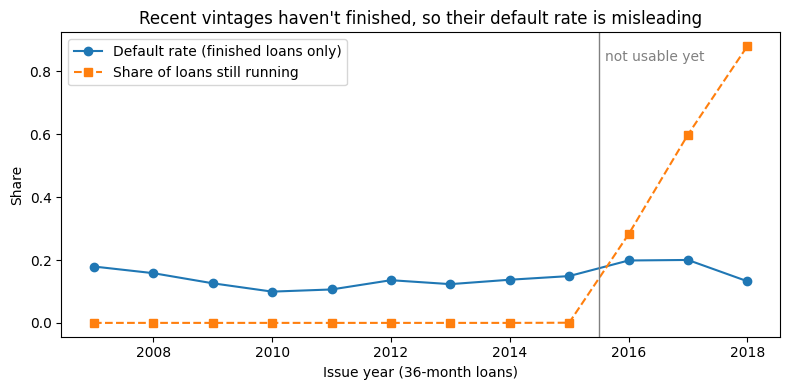

In [3]:
resolved = status_36m.loc[status_36m["status_group"].isin(["Defaulted", "Paid off"])]
by_year = pd.DataFrame({
    "default_rate_among_finished": resolved.groupby("issue_year")["status_group"].apply(lambda s: (s == "Defaulted").mean()),
    "share_unfinished": status_36m.groupby("issue_year")["status_group"].apply(lambda s: (s == "Unresolved").mean()),
})

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(by_year.index, by_year["default_rate_among_finished"], marker="o", label="Default rate (finished loans only)")
ax.plot(by_year.index, by_year["share_unfinished"], marker="s", linestyle="--", label="Share of loans still running")
ax.axvline(config.LAST_ISSUE_YEAR + 0.5, color="grey", linewidth=1)
ax.text(config.LAST_ISSUE_YEAR + 0.6, ax.get_ylim()[1] * 0.9, "not usable yet", color="grey")
ax.set_xlabel("Issue year (36-month loans)")
ax.set_ylabel("Share")
ax.set_title("Recent vintages haven't finished, so their default rate is misleading")
ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURES / "01_default_rate_by_vintage.png", dpi=150)
by_year

**What to look for:** for 2016-2018, most loans are still running, and among the few that *have* finished, defaults are over-represented (a loan can only finish early by defaulting or being repaid early). Either way, those years would bias the model.

That's why the sample stops at **2015**: a 36-month loan issued in December 2015 was due to finish by December 2018, the end of the data.

> **Interview angle:** "I restricted to 36-month loans issued up to 2015 so every loan had its full term to play out. Otherwise recent vintages are right-censored."

## The modelling dataset

`scripts/make_dataset.py` applies these rules and saves a smaller file. Here's what's left.

In [4]:
df = load_processed()
print(f"{len(df):,} loans, overall default rate {df['default'].mean():.2%}")
df.groupby("issue_year")["default"].agg(loans="size", default_rate="mean")

618,584 loans, overall default rate 13.90%


,loans,default_rate
issue_year,,
2007,251,0.1793
2008,1562,0.1581
2009,4716,0.1260
2010,8466,0.0995
2011,14101,0.1063
2012,43470,0.1358
2013,100422,0.1233
2014,162570,0.1373
2015,283026,0.1489


Two things to notice:

- **Volume grows fast** over time, so the latest year we can use (2015) is also the biggest. That makes it a good **out-of-time test set** (notebook 03).
- **The default rate isn't constant** across years. Lending Club's customer mix and the economy changed. A model trained on earlier years has to cope with that shift, which is exactly what out-of-time testing checks.

## Limitation to carry into the README

Basel PDs are **12-month** probabilities: will this borrower default in the next year? Our label is **lifetime**: did the loan default at any point in its 3 years? Lifetime PD is what IFRS 9 uses for loans whose credit risk has worsened (Stage 2), so it's not wrong, just a different horizon from IRB capital.